# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to five slides (one for each of the following topics _data and metrics_, _features_, _architectures_, _results_, _extra_); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

# Start

In [1]:
# imports
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

import re
from collections import Counter
from pathlib import Path

from IPython.display import display

pd.set_option("display.max_colwidth", None)

### Plotting settings

In [2]:
# plotting settings
LABELS = ["entailment", "neutral", "contradiction"]
LABEL_COLORS = {
    "entailment": "#2a78d6",
    "neutral": "#eb6834",
    "contradiction": "#1baf7a",
}

# some global style settings so that all plots look the same
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e6e5e1"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlelocation"] = "left"
plt.rcParams["legend.frameon"] = False

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save_figure(fig, name):
    fig.savefig(FIG_DIR / f"eda_{name}.png", dpi=200, bbox_inches="tight")

## EDA

In [3]:
# Multi-Genre Natural Language Inference (MultiNLI)

ds = load_dataset("nyu-mll/multi_nli")

# we put all three splits into one dataframe, with a column that says which split a row comes from
split_names = {
    "train": "train",
    "validation_matched": "dev matched",
    "validation_mismatched": "dev mismatched",
}
split_order = list(split_names.values())
columns = ["promptID", "pairID", "premise", "hypothesis", "genre", "label"]

frames = []
for hf_split, name in split_names.items():
    split_df = ds[hf_split].to_pandas()[columns]
    split_df["split"] = name
    frames.append(split_df)
df = pd.concat(frames, ignore_index=True)

# the label is stored as 0/1/2, so we also add the readable name
df["label_name"] = df["label"].map({0: "entailment", 1: "neutral", 2: "contradiction"})
df.head(3)

,promptID,pairID,premise,hypothesis,genre,label,split,label_name
0,31193,31193n,Conceptually cream skimming has two basic dimensions - product and geography.,Product and geography are what make cream skimming work.,government,1,train,neutral
1,101457,101457e,you know during the season and i guess at at your level uh you lose them to the next level if if they decide to recall the the parent team the Braves decide to call to recall a guy from triple A then a double A guy goes up to replace him and a single A guy goes up to replace him,You lose the things to the following level if the people recall.,telephone,0,train,entailment
2,134793,134793e,One of our number will carry out your instructions minutely.,A member of my team will execute your orders with immense precision.,fiction,0,train,entailment


In [4]:
# some basic numbers per split
rows = []
for split in split_order:
    part = df[df["split"] == split]
    rows.append({
        "split": split,
        "pairs": len(part),
        "unique premises": part["premise"].nunique(),
        "genres": part["genre"].nunique(),
        "no gold label (-1)": (part["label"] == -1).sum(),
        "empty premise": (part["premise"].str.strip() == "").sum(),
        "empty hypothesis": (part["hypothesis"].str.strip() == "").sum(),
        "duplicate pairs": part.duplicated(["premise", "hypothesis"]).sum(),
    })

pd.DataFrame(rows).set_index("split")

,pairs,unique premises,genres,no gold label (-1),empty premise,empty hypothesis,duplicate pairs
split,,,,,,,
train,392702,128144,5,0,0,0,125
dev matched,9815,3334,5,0,0,0,0
dev mismatched,9832,3335,5,0,0,0,2


The number of unique premises is 1/3 of the total amount of pairs in the dataset. This is because three annotators were shown one premise and asked to write one hypothesis per label

### Label Distribution

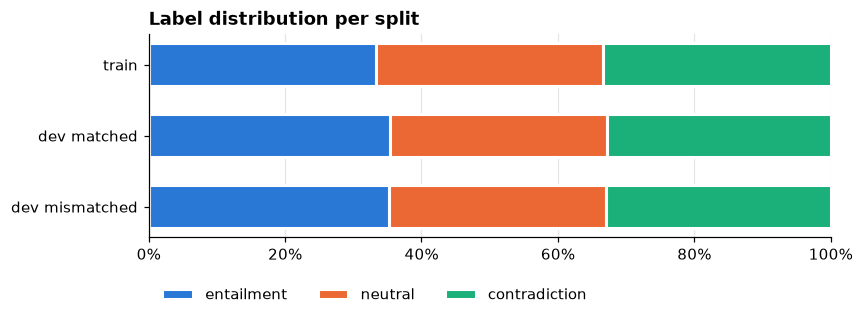

label_name,entailment,neutral,contradiction
split,,,
train,130899,130900,130903
dev matched,3479,3123,3213
dev mismatched,3463,3129,3240


label_name,entailment,neutral,contradiction
split,,,
train,33.3,33.3,33.3
dev matched,35.4,31.8,32.7
dev mismatched,35.2,31.8,33.0


In [5]:
# count how often each label occurs per split, and convert to percentages
label_counts = pd.crosstab(df["split"], df["label_name"])
label_counts = label_counts.loc[split_order, LABELS]
label_percentages = label_counts.div(label_counts.sum(axis=1), axis=0)

# stacked horizontal bar chart with one bar per split
fig, ax = plt.subplots(figsize=(8, 2.4))
left = np.zeros(len(split_order))
for label in LABELS:
    ax.barh(split_order, label_percentages[label], left=left, height=0.6,
            color=LABEL_COLORS[label], edgecolor="white", linewidth=2, label=label)
    left = left + label_percentages[label].values

ax.invert_yaxis()  # train on top
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Label distribution per split")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.18))
save_figure(fig, "label_balance")
plt.show()

display(label_counts)
display((label_percentages * 100).round(1))

### Genres

In [6]:
# number of examples per genre in each split
# (the dev mismatched genres don't appear in train, so we sort by train first and then by dev mismatched)
genre_counts = pd.crosstab(df["genre"], df["split"])
genre_counts = genre_counts[split_order]
genre_counts = genre_counts.sort_values(["train", "dev mismatched"], ascending=False)
display(genre_counts)

# label percentages per genre
genre_labels = pd.crosstab(df["genre"], df["label_name"], normalize="index")
genre_labels = genre_labels.loc[genre_counts.index, LABELS]
display((genre_labels * 100).round(1))

split,train,dev matched,dev mismatched
genre,,,
telephone,83348,1966,0
government,77350,1945,0
travel,77350,1976,0
fiction,77348,1973,0
slate,77306,1955,0
letters,0,0,1977
facetoface,0,0,1974
nineeleven,0,0,1974
oup,0,0,1961


label_name,entailment,neutral,contradiction
genre,,,
telephone,33.4,33.3,33.3
government,33.4,33.3,33.3
travel,33.4,33.3,33.3
fiction,33.4,33.3,33.3
slate,33.4,33.3,33.3
letters,37.4,29.6,33.0
facetoface,34.4,32.3,33.3
nineeleven,35.4,31.6,33.0
oup,35.0,32.7,32.3


### Easy Tokenizer to check composition per label

In [7]:
# simple tokenizer: lowercase the text and split it into words and punctuation.
# "n't" is split off as its own token, so "don't" becomes ["do", "n't"]
TOKEN_PATTERN = re.compile(r"\w+(?=n't)|n't|\w+|[^\w\s]")

def tokenize(text):
    return TOKEN_PATTERN.findall(text.lower())

df["premise_tokens"] = df["premise"].apply(tokenize)
df["hypothesis_tokens"] = df["hypothesis"].apply(tokenize)
df["premise_len"] = df["premise_tokens"].apply(len)
df["hypothesis_len"] = df["hypothesis_tokens"].apply(len)

# sentence length statistics (in tokens) per split
length_stats = df.groupby("split")[["premise_len", "hypothesis_len"]].describe()
length_stats.loc[split_order].T.round(1)

split                    train  dev matched  dev mismatched
premise_len    count  392702.0       9815.0          9832.0
               mean       23.2         22.6            23.3
               std        16.0         15.9            15.1
               min         1.0          1.0             3.0
               25%        12.0         12.0            13.0
               50%        20.0         19.0            20.0
               75%        30.0         30.0            30.0
               max       415.0        208.0           151.0
hypothesis_len count  392702.0       9815.0          9832.0
               mean       11.5         11.5            12.4
               std         4.7          4.7             5.0
               min         1.0          1.0             2.0
               25%         8.0          8.0             9.0
               50%        11.0         11.0            12.0
               75%        14.0         14.0            15.0
               max        71.0         51.0            68.0

### Negation words

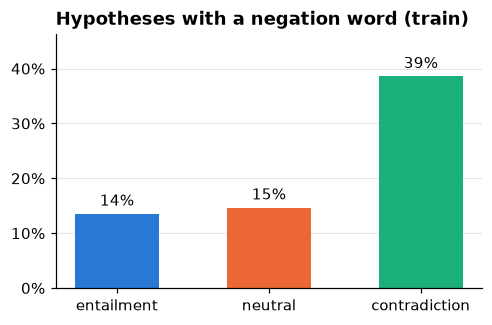

negation words: cannot, n't, neither, never, no, nobody, none, nor, not, nothing, nowhere


In [8]:
NEGATION_WORDS = {"not", "n't", "no", "never", "nobody", "nothing", "none", "nowhere", "neither", "nor", "cannot"}

def has_negation(tokens):
    return any(token in NEGATION_WORDS for token in tokens)

df["hyp_has_negation"] = df["hypothesis_tokens"].apply(has_negation)
train = df[df["split"] == "train"]

# percentage of hypotheses with a negation word, per label (train only)
negation_rate = train.groupby("label_name")["hyp_has_negation"].mean()
negation_rate = negation_rate[LABELS]

fig, ax = plt.subplots(figsize=(5, 3))
colors = [LABEL_COLORS[label] for label in LABELS]
bars = ax.bar(LABELS, negation_rate, color=colors, width=0.55)
ax.bar_label(bars, labels=[f"{rate:.0%}" for rate in negation_rate], padding=3)
ax.set_title("Hypotheses with a negation word (train)")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, negation_rate.max() * 1.2)  # leave some room for the labels above the bars
ax.grid(axis="x", visible=False)
save_figure(fig, "negation_by_label")
plt.show()

print("negation words:", ", ".join(sorted(NEGATION_WORDS)))

### Most label-specific hypothesis words

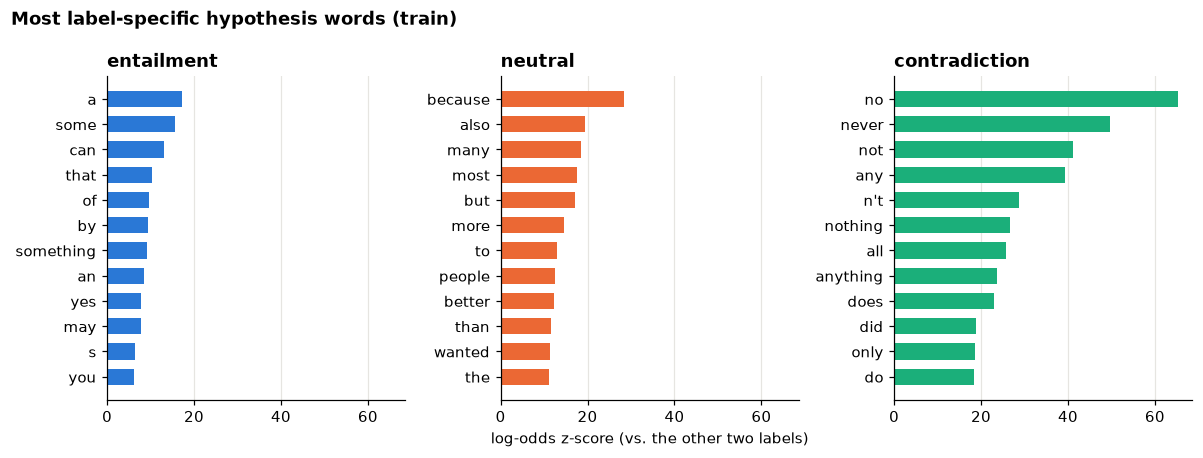

In [9]:
# Which hypothesis words are typical for one label compared to the other two?
# We use the log-odds ratio with an informative Dirichlet prior (Monroe et al., 2008).
# A high z-score means the word appears a lot more often for that label.

def log_odds_z_scores(counts_a, counts_b, prior, min_count=50):
    total_a = sum(counts_a.values())
    total_b = sum(counts_b.values())
    total_prior = sum(prior.values())

    scores = {}
    for word, prior_count in prior.items():
        # skip rare words and tokens without letters (punctuation, numbers)
        if prior_count < min_count or not re.search("[a-z]", word):
            continue

        a = counts_a[word] + prior_count
        b = counts_b[word] + prior_count
        log_odds_a = np.log(a / (total_a + total_prior - a))
        log_odds_b = np.log(b / (total_b + total_prior - b))
        variance = 1 / a + 1 / b
        scores[word] = (log_odds_a - log_odds_b) / np.sqrt(variance)

    return pd.Series(scores).sort_values(ascending=False)


# count the hypothesis words for each label
word_counts = {}
for label in LABELS:
    counter = Counter()
    for tokens in train.loc[train["label_name"] == label, "hypothesis_tokens"]:
        counter.update(tokens)
    word_counts[label] = counter

all_word_counts = word_counts["entailment"] + word_counts["neutral"] + word_counts["contradiction"]

# compare each label against the other two labels combined
z_scores = {}
for label in LABELS:
    other_counts = all_word_counts - word_counts[label]
    z_scores[label] = log_odds_z_scores(word_counts[label], other_counts, all_word_counts)

# plot the top 12 words per label
fig, axes = plt.subplots(1, 3, figsize=(11, 4.2), sharex=True)
for ax, label in zip(axes, LABELS):
    top_words = z_scores[label].head(12)
    top_words = top_words[::-1]  # reverse, so the highest score is at the top
    ax.barh(top_words.index, top_words.values, color=LABEL_COLORS[label], height=0.65)
    ax.set_title(label)
    ax.grid(axis="y", visible=False)

axes[1].set_xlabel("log-odds z-score (vs. the other two labels)")
fig.suptitle("Most label-specific hypothesis words (train)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_figure(fig, "label_words")
plt.show()